# 01 · Superposition and entanglement

**Stage 2: the Hadamard gate.** A qubit's state is $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$
with complex amplitudes where $|\alpha|^2 + |\beta|^2 = 1$. Measuring it gives `0` with probability
$|\alpha|^2$ and `1` with probability $|\beta|^2$, and the superposition is destroyed in the process.

The **Hadamard** gate $H$ sends $|0\rangle \to \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle)$: an equal
superposition. One measurement only gives you one random bit, so we repeat the experiment many
times (**shots**) and look at the histogram. It should be close to 50/50.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

sim = AerSimulator()   # local, noiseless simulator (runs on your laptop)
SHOTS = 4096
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed series order: blue, orange, aqua

def run(qc, shots=SHOTS):
    """Compile a circuit for the simulator, run it, and return the measurement counts."""
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

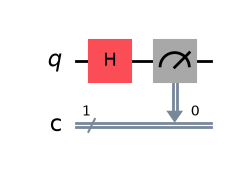

In [2]:
had = QuantumCircuit(1, 1)   # 1 qubit, 1 classical bit to store the result
had.h(0)                     # |0> -> (|0> + |1>)/sqrt(2): equal superposition
had.measure(0, 0)            # collapse: read 0 or 1, each with probability |1/sqrt(2)|^2 = 0.5
had.draw("mpl")

Before measuring, we can look at the exact **statevector**. A simulator can do this, but real
hardware can't. Take the circuit, remove the final measurement, and compute the amplitudes:

In [3]:
sv = Statevector.from_instruction(had.remove_final_measurements(inplace=False))
print("amplitudes   :", np.round(sv.data, 4))         # [0.7071, 0.7071] = 1/sqrt(2) each
print("probabilities:", {str(k): round(float(v), 3) for k, v in sv.probabilities_dict().items()})   # {'0': 0.5, '1': 0.5}

amplitudes   : [0.7071+0.j 0.7071+0.j]
probabilities: {'0': 0.5, '1': 0.5}


P(0) = 0.4934   (expected 0.5 ± 0.0078)


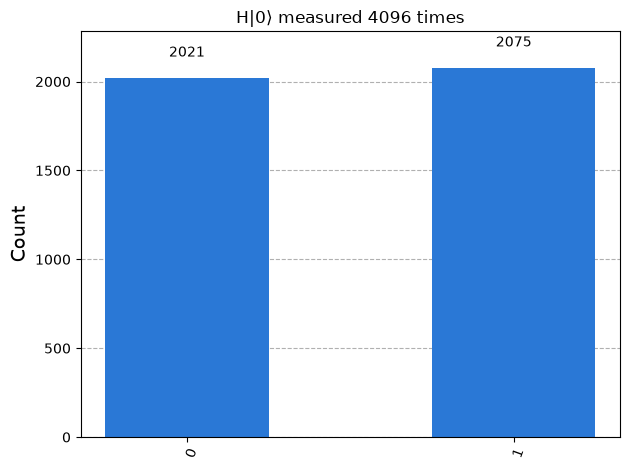

In [4]:
counts = run(had)
p0 = counts.get("0", 0) / SHOTS
# Each shot is a coin flip, so the measured fraction scatters by about sqrt(p(1-p)/N)
print(f"P(0) = {p0:.4f}   (expected 0.5 ± {np.sqrt(0.25 / SHOTS):.4f})")
plot_histogram(counts, color=COLORS[0], title=f"H|0⟩ measured {SHOTS} times")

**How many shots do you need?** The statistical error shrinks like $1/\sqrt{N}$, so 100× more
shots buys you 10× more precision:

In [5]:
for n in [10, 100, 1_000, 10_000, 100_000]:
    c = run(had, shots=n)
    print(f"{n:>7} shots: P(0) = {c.get('0', 0) / n:.4f}")

     10 shots: P(0) = 0.7000
    100 shots: P(0) = 0.5600
   1000 shots: P(0) = 0.5100


  10000 shots: P(0) = 0.5050


 100000 shots: P(0) = 0.4985


---
## Stage 3: the Bell pair (entanglement)

Two steps:
1. `H` on qubit 0 gives $\tfrac{1}{\sqrt2}(|0\rangle+|1\rangle)\otimes|0\rangle$.
2. `CNOT` (control q0, target q1) flips q1 **only if** q0 is 1, giving
   $\tfrac{1}{\sqrt2}(|00\rangle + |11\rangle)$.

That's the Bell state $|\Phi^+\rangle$. Each qubit on its own is a 50/50 coin, but the two coins
**always agree**: you only ever see `00` or `11`, never `01` or `10`. You can't write this state as
"qubit 0's state × qubit 1's state", and that's what *entangled* means.

> **Bit ordering:** Qiskit prints results as `c1c0`, so qubit 0 is the **rightmost** character.
> For `00`/`11` it doesn't matter, but it will in later notebooks.

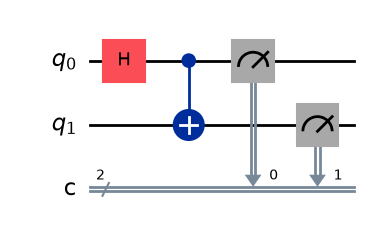

In [6]:
bell = QuantumCircuit(2, 2)
bell.h(0)                      # q0 into superposition
bell.cx(0, 1)                  # copy q0's *basis value* onto q1 -> (|00> + |11>)/sqrt(2)
bell.measure([0, 1], [0, 1])   # q0 -> c0, q1 -> c1
bell.draw("mpl")

In [7]:
sv = Statevector.from_instruction(bell.remove_final_measurements(inplace=False))
print("probabilities:", {str(k): round(float(v), 3) for k, v in sv.probabilities_dict().items()})   # only '00' and '11'

probabilities: {'00': 0.5, '11': 0.5}


To see why the correlation matters, compare against a **product state**: `H` on *both* qubits
with no CNOT. Each qubit is still 50/50, but they're independent, so all four outcomes appear.

Bell pair    : qubits agree 100.0% of the time
Product state: qubits agree 48.6% of the time


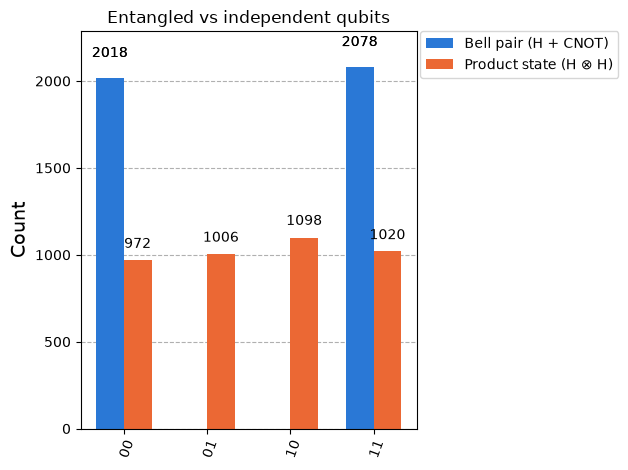

In [8]:
product = QuantumCircuit(2, 2)
product.h([0, 1])              # two independent coins, no entanglement
product.measure([0, 1], [0, 1])

bell_counts = run(bell)
product_counts = run(product)

def agreement(c):
    """Fraction of shots where both qubits gave the same answer."""
    return (c.get("00", 0) + c.get("11", 0)) / sum(c.values())

print(f"Bell pair    : qubits agree {agreement(bell_counts):.1%} of the time")
print(f"Product state: qubits agree {agreement(product_counts):.1%} of the time")
plot_histogram([bell_counts, product_counts], legend=["Bell pair (H + CNOT)", "Product state (H ⊗ H)"],
               color=COLORS[:2], title="Entangled vs independent qubits")

**Bonus: is this just classical correlation?** Two coins that were secretly glued together
would also always agree. But if we measure in a *different basis* (apply `H` to both qubits
before measuring, which is the X basis), $|\Phi^+\rangle$ **still** gives perfectly correlated results.
A classical "glued coins" model can't match quantum predictions in every basis at once. Bell
inequalities turn this into a rigorous test.

In [9]:
bell_x = QuantumCircuit(2, 2)
bell_x.h(0); bell_x.cx(0, 1)   # same Bell pair
bell_x.h([0, 1])               # rotate the measurement basis Z -> X on both qubits
bell_x.measure([0, 1], [0, 1])
cx_counts = run(bell_x)
print(cx_counts, f"-> agree {agreement(cx_counts):.1%}")

{'11': 2041, '00': 2055} -> agree 100.0%
